# Etapa 2 — Prova de Conceito dos Modelos de Recomendação
## Cozinha Consciente — Sistema de Recomendação Híbrido de Receitas

Objetivo: treinar uma versão inicial de cada abordagem sobre a base real e verificar se a técnica
proposta é viável. Este notebook usa os **parâmetros iniciais** definidos na Etapa 2; o ajuste
desses parâmetros é feito no notebook `03_ajuste_e_reavaliacao.ipynb`.

> **Nota de revisão do protocolo.** Na primeira execução da prova de conceito, o item relevante
> ocupava sempre a posição 0 da lista de candidatos e os desempates de escore o favoreciam, o que
> inflava modelos com muitos escores iguais a zero (principalmente o ItemKNN). O protocolo foi
> corrigido: a posição do item relevante agora é aleatória e o desempate é estável. Os números
> abaixo já usam o protocolo corrigido.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.data_preparation import build_dataset, describe
from src.recommenders import (Dataset, PopularityRecommender, ItemKNNRecommender,
                              SVDRecommender, ContentTFIDFRecommender, HybridRecommender)
from src.evaluate import evaluate, comparison_table

# parâmetros INICIAIS da prova de conceito (Etapa 2)
SVD_FATORES_INICIAL = 64
KNN_VIZINHOS_INICIAL = 200
PESOS_INICIAIS = {"svd": 0.5, "itemknn": 0.3, "content": 0.2}
LAMBDA_INICIAL = 0.30

## 1. Preparação da base
Deduplicação, descarte de nota 0, feedback implícito (nota ≥ 4), k-core 5/5, decomposição da coluna
`nutrition` e divisão temporal *leave-one-out* (última interação → teste, penúltima → validação).

In [2]:
recipes, train, valid, test = build_dataset()
pd.Series(describe(recipes, train, valid, test))

receitas_no_catalogo                  37851.000000
usuarios                              16043.000000
itens_com_interacao                   37850.000000
interacoes_treino                    466521.000000
interacoes_validacao                  16040.000000
interacoes_teste                      16039.000000
densidade_matriz_pct                      0.076828
esparsidade_pct                          99.923172
interacoes_por_usuario_media             29.080000
indice_nutricional_medio_catalogo         0.540200
dtype: float64

## 2. Matriz usuário-item e treinamento dos modelos iniciais

In [3]:
ds = Dataset(train, recipes)
print("Matriz usuário-item:", ds.R.shape, "| interações:", ds.R.nnz)

pop = PopularityRecommender().fit(ds)
knn = ItemKNNRecommender().fit(ds, neighbors=KNN_VIZINHOS_INICIAL)
svd = SVDRecommender().fit(ds, factors=SVD_FATORES_INICIAL)
cnt = ContentTFIDFRecommender().fit(ds)

comps = {"svd": svd, "itemknn": knn, "content": cnt}
hyb = HybridRecommender(comps, weights=PESOS_INICIAIS, health_lambda=0.0, norm="minmax").fit(ds)
hyb_h = HybridRecommender(comps, weights=PESOS_INICIAIS, health_lambda=LAMBDA_INICIAL, norm="minmax").fit(ds)

Matriz usuário-item: (16043, 37850) | interações: 466521


## 3. Avaliação (conjunto de teste)
Para cada caso de teste: 1 item relevante + 99 negativos não vistos, em posição aleatória; métricas @10.

In [4]:
results = [evaluate(m, ds, test) for m in (pop, knn, svd, cnt, hyb, hyb_h)]
table = comparison_table(results)
table[["HitRate@10", "Precision@10", "MAP@10", "NDCG@10", "Cobertura_catalogo",
       "Vies_popularidade", "IndiceNutricional@10"]]

,HitRate@10,Precision@10,MAP@10,NDCG@10,Cobertura_catalogo,Vies_popularidade,IndiceNutricional@10
modelo,,,,,,,
Popularidade,0.5072,0.0507,0.2722,0.3277,0.1718,0.0681,0.5258
ItemKNN (cosseno),0.1801,0.0180,0.0761,0.1003,0.9657,0.0210,0.5416
PureSVD (fatoracao),0.3494,0.0349,0.1910,0.2282,0.7381,0.0421,0.5391
Conteudo (TF-IDF),0.2128,0.0213,0.0786,0.1095,0.7135,0.0197,0.5678
Hibrido (sem reordenacao),0.3530,0.0353,0.1757,0.2171,0.8634,0.0373,0.5453
Hibrido (lambda=0.30),0.3315,0.0332,0.1679,0.2062,0.8103,0.0355,0.6261


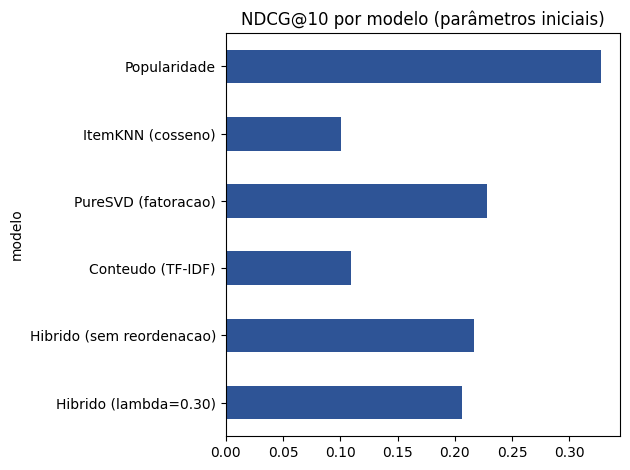

In [5]:
ax = table["NDCG@10"].plot(kind="barh", color="#2E5496")
ax.set_title("NDCG@10 por modelo (parâmetros iniciais)")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

## 4. Discussão da prova de conceito

- A **popularidade** foi o melhor modelo isolado (HitRate 0,507; NDCG 0,328). Isso é esperado no
  protocolo com negativos sorteados ao acaso: itens populares quase sempre superam itens aleatórios.
- O **ItemKNN** ficou muito abaixo (HitRate 0,180, próximo ao acaso, que é 0,10): com a poda para
  200 vizinhos, muitos candidatos recebem escore zero. Sua cobertura de catálogo é a maior (96,6%).
- O **SVD** ficou em posição intermediária (HitRate 0,349) e o **conteúdo TF-IDF** foi o mais fraco
  entre os não colaborativos (0,213), mas é o que mais favorece receitas saudáveis (índice 0,568).
- O **híbrido inicial** (pesos definidos a priori, sem componente de popularidade) ficou *abaixo* da
  popularidade e, em NDCG, até do SVD isolado: pesos fixos escolhidos sem validação não funcionam.
- A **reordenação nutricional** (λ = 0,30) elevou o índice nutricional médio de 0,545 para 0,626
  (+14,8%) ao custo de 5,0% de NDCG, o que confirma a viabilidade do compromisso relevância ×
  saudabilidade.

**Conclusão:** a técnica é viável, mas o pipeline precisa de ajustes (hiperparâmetros, pesos do
híbrido, normalização e escolha de λ com critério explícito). Isso é feito na Etapa 3, sempre
usando a **validação** para decidir e o **teste** apenas para a reavaliação final.